# OCR / document models: inference test (CPU)

Runs four document models on 5 invoices and 5 receipts (`../sample_docs/`) and saves every output.

| Model | Hugging Face id | What you get back | Runs on CPU? |
|---|---|---|---|
| Tesseract 5 | (classic OCR engine, not a neural LLM) | plain text + a box and confidence for every word | **yes**, ~1–3 s per page |
| GOT-OCR 2.0 | `stepfun-ai/GOT-OCR-2.0-hf` | plain text (or Markdown/LaTeX in "format" mode) | **yes, in bfloat16**, ~40–60 s per page. float32 needs ~4 GB+ free RAM. |
| SmolDocling | `docling-project/SmolDocling-256M-preview` | DocTags (text + layout + tables), converted to Markdown | **yes**, ~30–70 s per page |
| LayoutLM doc-QA | `impira/layoutlm-document-qa` | an answer to a question ("What is the invoice number?") | **yes**, ~1 s per question. **Needs Tesseract** for the words and boxes. |

A GPU is not required. If one is available it is used automatically, and GOT/SmolDocling become several times faster.

**How the models are scored:** the sample documents come with an answer key (invoice number, date, tax ids, IBAN, totals;
receipt totals, cash and change).
- **OCR models** (Tesseract, GOT, SmolDocling): the score is the % of answer-key values that appear exactly in the model's text (spaces ignored).
- **LayoutLM:** asked one question per answer-key field, and the answer is compared with the key.

In [1]:
import os
# Use exactly one GPU. Must be set before torch is imported. Check `nvidia-smi` and pick an idle card.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "1")

import gc, json, os, sys, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import pytesseract
import torch
from PIL import Image
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
# Jupyter kernels don't always have the conda env's bin/ on PATH, so point pytesseract at the env's tesseract
_tess = Path(sys.prefix) / "bin" / "tesseract"
if _tess.exists():
    pytesseract.pytesseract.tesseract_cmd = str(_tess)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "", "| CUDA_VISIBLE_DEVICES =", os.environ["CUDA_VISIBLE_DEVICES"], "| torch", torch.__version__, "| tesseract", pytesseract.get_tesseract_version())

DOCS = Path("../sample_docs")
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

device: cuda NVIDIA A100-SXM4-40GB | CUDA_VISIBLE_DEVICES = 1 | torch 2.6.0+cu124 | tesseract 5.5.2


## Settings

In [2]:
MAX_NEW_TOKENS = 2048          # cap on generated tokens for GOT / SmolDocling (a full invoice needs ~300-700)
GOT_DTYPE = torch.bfloat16     # bfloat16 halves memory on CPU; use torch.float32 if you have ~4 GB+ free RAM
NAMES = [f"invoice_{i}" for i in range(1, 6)] + [f"receipt_{i}" for i in range(1, 6)]
IMAGES = {n: Image.open(DOCS / f"{n}.jpg").convert("RGB") for n in NAMES}

## The 10 test documents

- **Invoices 1–5:** synthetic invoices from `katanaml-org/invoices-donut-data-v1`. They are clean, high-resolution (2481×3508) printed pages.
- **Receipts 1–5:** real phone photos of Indonesian receipts from `naver-clova-ix/cord-v2`. They are small, crumpled and tilted, and much harder.

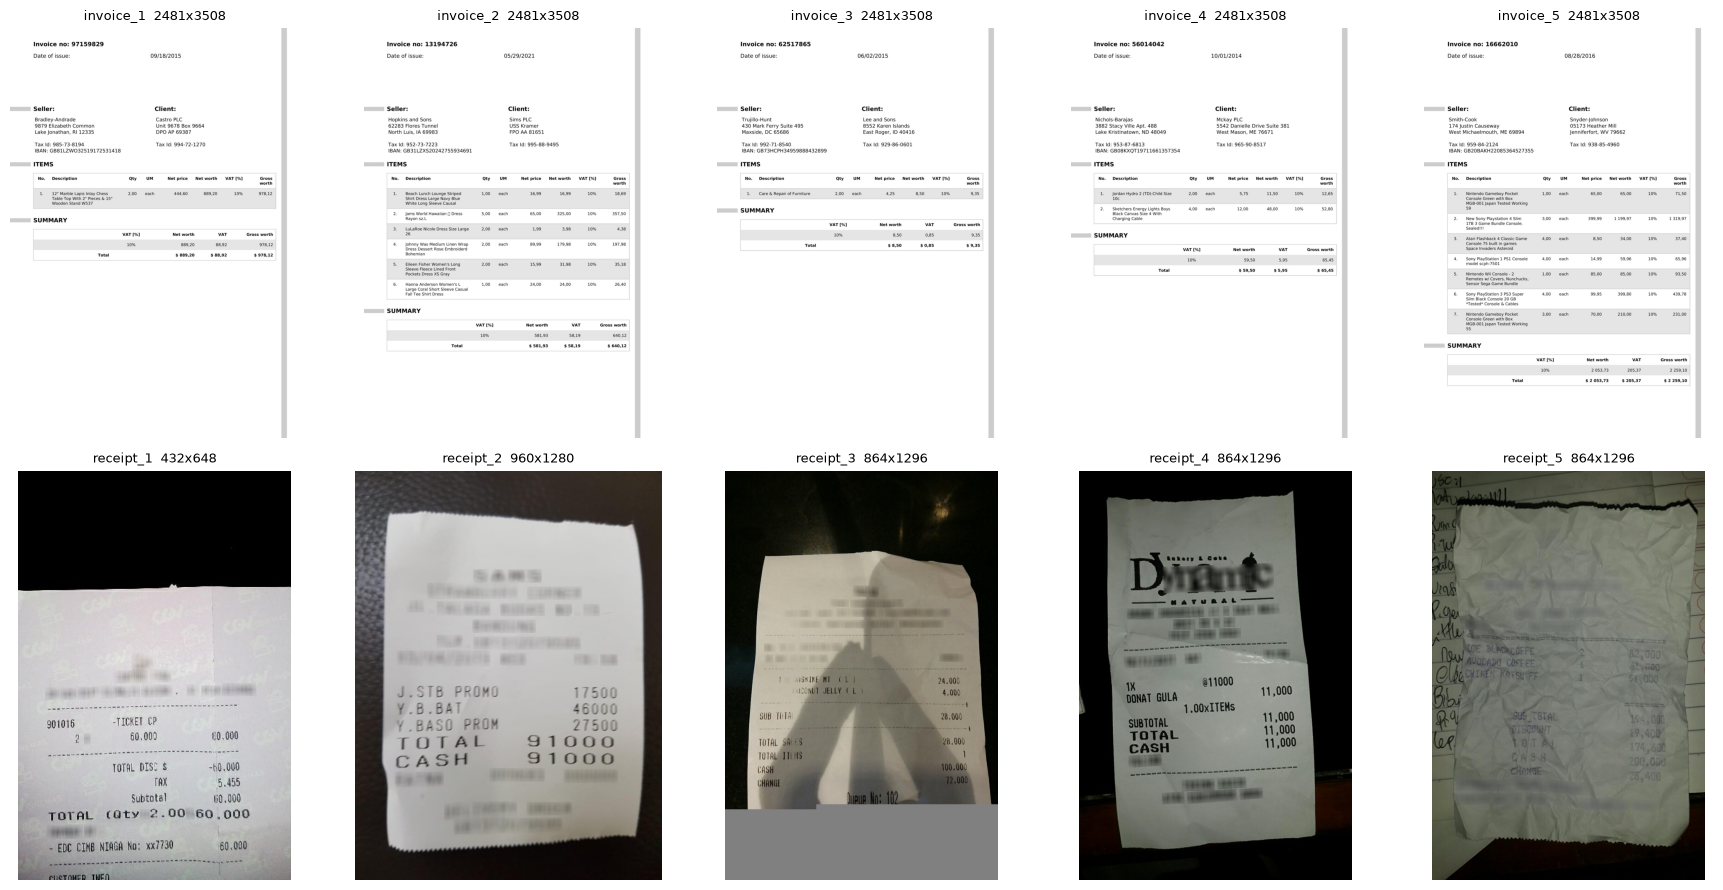

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(18, 9))
for ax, (name, img) in zip(axes.flat, IMAGES.items()):
    ax.imshow(img); ax.set_title(f"{name}  {img.size[0]}x{img.size[1]}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## Answer key

Taken from the datasets' ground-truth JSON (`invoice_rows.json`, `receipt_rows.json`). Each document has a few fields
with a known value, and each field has a question used for LayoutLM.

In [4]:
QUESTIONS = {
    "invoice_no": "What is the invoice number?",
    "invoice_date": "What is the date of issue?",
    "seller_tax_id": "What is the seller's tax id?",
    "iban": "What is the IBAN?",
    "total_gross_worth": "What is the total gross worth?",
    "total_price": "What is the total price?",
    "subtotal_price": "What is the subtotal?",
    "cashprice": "How much cash was paid?",
    "changeprice": "How much is the change?",
}

def clean_value(v):
    return v.replace("$", "").strip()

KEY = {}
for kind, file in [("invoice", "invoice_rows.json"), ("receipt", "receipt_rows.json")]:
    rows = json.loads((DOCS / file).read_text())["rows"]
    for r in rows:
        gt = json.loads(r["row"]["ground_truth"])["gt_parse"]
        flat = {**gt.get("header", {}), **gt.get("summary", {}), **gt.get("sub_total", {}), **gt.get("total", {})}
        KEY[f"{kind}_{r['row_idx'] + 1}"] = {f: clean_value(flat[f]) for f in QUESTIONS if f in flat}

display(pd.DataFrame(KEY).T.fillna(""))

,invoice_no,invoice_date,seller_tax_id,iban,total_gross_worth,total_price,subtotal_price,cashprice,changeprice
invoice_1,97159829,09/18/2015,985-73-8194,GB81LZWO32519172531418,"978,12",,,,
invoice_2,13194726,05/29/2021,952-73-7223,GB31LZX520242755934691,"640,12",,,,
invoice_3,62517865,06/02/2015,992-71-8540,GB73HCPH34959888432899,"9,35",,,,
invoice_4,56014042,10/01/2014,953-87-6813,GB08KXQT197119711661357354,"65,45",,,,
invoice_5,16662010,08/28/2016,959-84-2124,GB20BAKH22085364527355,"2259,10",,,,
receipt_1,,,,,,60.000,60.000,,
receipt_2,,,,,,91000,,91000,
receipt_3,,,,,,"28,000","28,000","100,000","72,000"
receipt_4,,,,,,"11,000","11,000","11,000",
receipt_5,,,,,,"174,600","194,000","200,000","25,400"


## Helpers: scoring and saving

In [5]:
norm = lambda s: "".join(str(s).split()).lower()

RESULTS, TIMES = {}, {}   # RESULTS[model][doc] = text

def record(model, name, text, seconds, ext="txt"):
    RESULTS.setdefault(model, {})[name] = text
    TIMES.setdefault(model, {})[name] = seconds
    d = OUT / model; d.mkdir(exist_ok=True)
    (d / f"{name}.{ext}").write_text(text)

def fields_found(name, text):
    t = norm(text)
    return {f: norm(v) in t for f, v in KEY[name].items()}

def show_model(model):
    rows = []
    for name, text in RESULTS[model].items():
        found = fields_found(name, text)
        rows.append({"doc": name, "fields found": f"{sum(found.values())}/{len(found)}",
                     "missed": ", ".join(f for f, ok in found.items() if not ok),
                     "chars": len(text), "seconds": round(TIMES[model][name], 1)})
    df = pd.DataFrame(rows).set_index("doc")
    display(df)
    found = [fields_found(n, t) for n, t in RESULTS[model].items()]
    total = sum(len(f) for f in found); ok = sum(sum(f.values()) for f in found)
    print(f"{model}: {ok}/{total} answer-key values found ({ok / total:.0%}) | avg {df.seconds.mean():.1f}s per page")

def free(*objs):
    for o in objs: del o
    gc.collect()

## 1. Tesseract (classic OCR)

> **What it does:** Tesseract is a classic OCR engine (originally from HP, now open source and maintained by Google contributors).
> It finds lines of text, then recognizes each line with a small LSTM network. It is fast, light and runs anywhere,
> but it only reads text: no understanding of tables, layout or meaning, and it struggles with photos, tilt and crumpled paper.
>
> | | |
> |---|---|
> | **Input** | an image (+ optional language, e.g. `lang="eng"`) |
> | **Output** | `image_to_string` → plain text; `image_to_data` → every word with its box `(left, top, width, height)` and confidence 0–100 |
> | **Needs from you** | just the image. It is a system program, not a pip package: `conda install tesseract` or `apt install tesseract-ocr`, plus `pip install pytesseract`. |
>
> **Example (invoice_1):** `Invoice no: 97159829` … `IBAN: GB81LZW0O32519172531418`. Note the `0O` misread of the `O` in the real IBAN.

In [6]:
for name, img in IMAGES.items():
    t = time.time()
    text = pytesseract.image_to_string(img)
    record("tesseract", name, text, time.time() - t)
show_model("tesseract")

print("\n--- invoice_1 (first 600 chars) ---\n", RESULTS["tesseract"]["invoice_1"][:600])
print("\n--- receipt_2 ---\n", RESULTS["tesseract"]["receipt_2"][:600])

,fields found,missed,chars,seconds
doc,,,,
invoice_1,4/5,iban,540,1.2
invoice_2,4/5,iban,1027,1.9
invoice_3,5/5,,473,1.1
invoice_4,4/5,iban,623,1.4
invoice_5,5/5,,1247,2.4
receipt_1,2/2,,152,0.3
receipt_2,0/2,"total_price, cashprice",0,0.4
receipt_3,2/4,"cashprice, changeprice",135,0.5
receipt_4,0/3,"total_price, subtotal_price, cashprice",56,0.4


tesseract: 26/40 answer-key values found (65%) | avg 1.0s per page

--- invoice_1 (first 600 chars) ---
 Invoice no: 97159829

Date of issue:

Seller:

Bradley-Andrade
9879 Elizabeth Common
Lake Jonathan, RI 12335

Tax Id: 985-73-8194
IBAN: GB81LZW0O32519172531418

ITEMS
No. Description Qty
1. 12" Marble Lapis Inlay Chess 2,00
Table Top With 2" Pieces & 15"
Wooden Stand W537
SUMMARY
VAT [%]

10%

Total

UM

each

09/18/2015

Client:

Castro PLC
Unit 9678 Box 9664
DPO AP 69387

Tax Id: 994-72-1270

Net price

Net worth VAT [%]
444,60 889,20 10%
Net worth VAT
889,20 88,92
$ 889,20 $ 88,92

Gross
worth

978,12

Gross worth
978,12

$ 978,12


--- receipt_2 ---
 


**Word boxes and confidences** (`image_to_data`). This is the part LayoutLM uses. The colour shows confidence:
green ≥ 80, orange 50–80, red < 50.

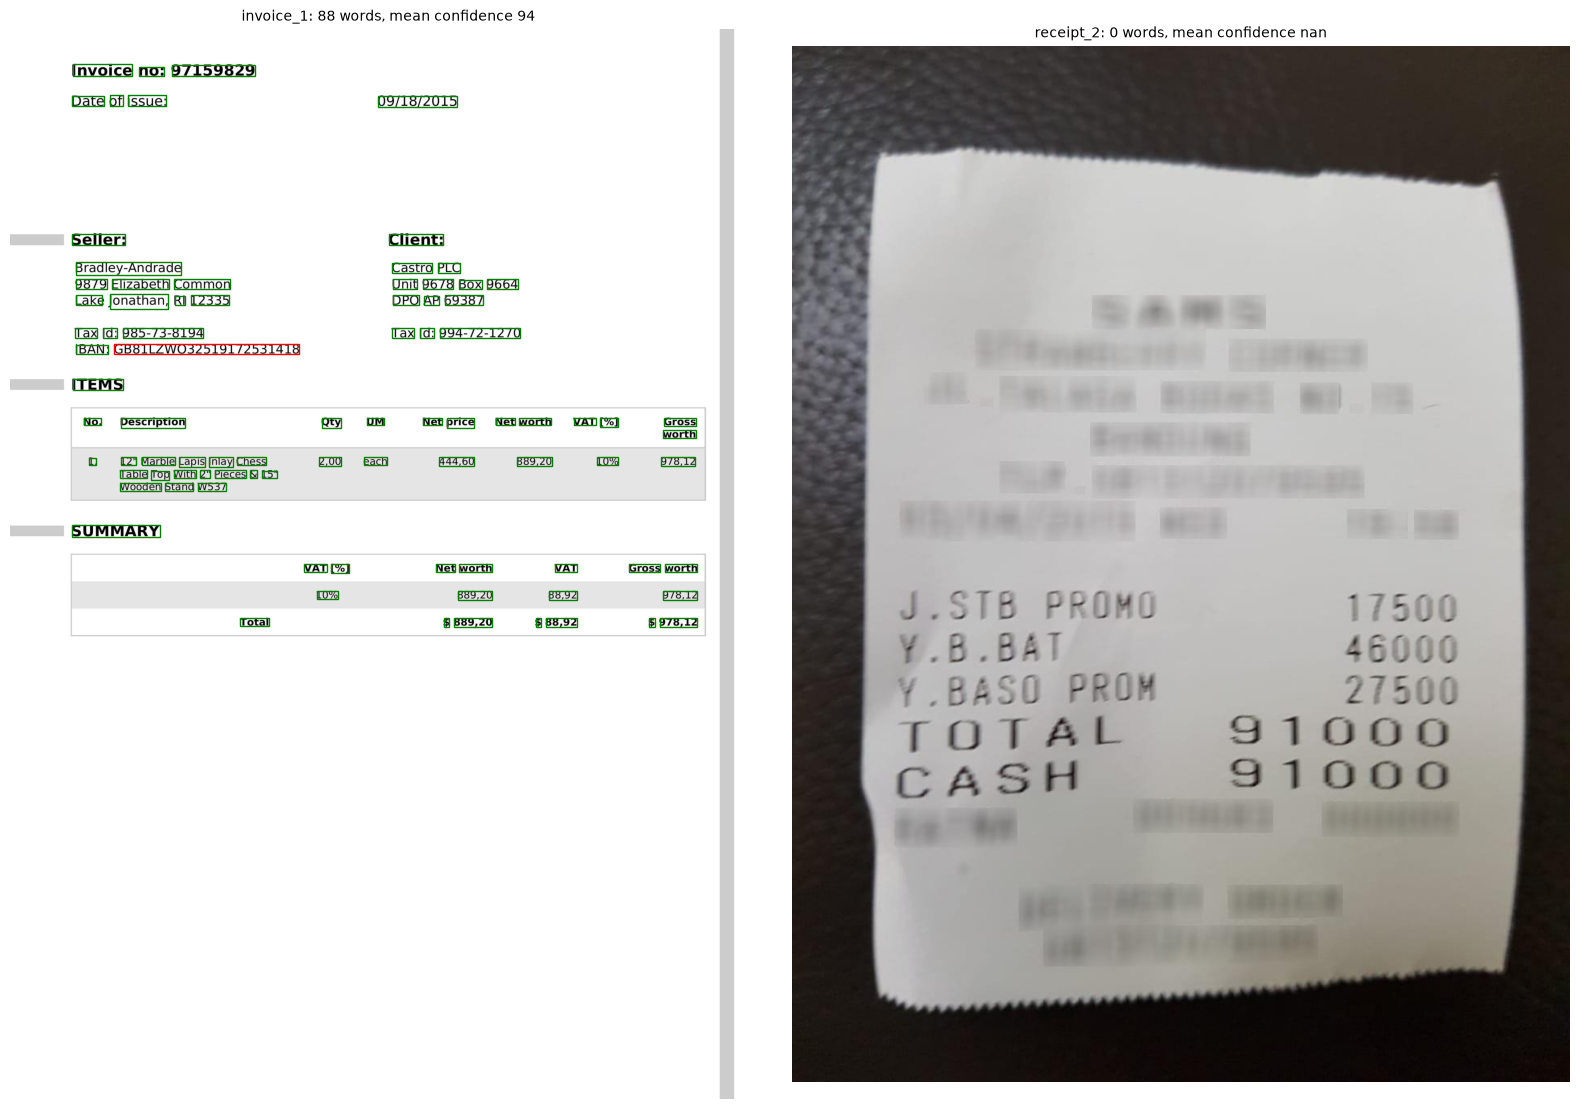

,left,top,width,height,conf,text
4,205,115,195,39,95.999184,Invoice
5,424,125,80,29,95.481201,no:
6,530,116,272,38,96.507248,97159829
10,204,218,104,35,95.426003,Date
11,327,217,42,36,95.426003,of
12,387,217,124,36,96.570259,issue:
16,204,670,173,39,96.550812,Seller:
20,216,765,344,41,91.794754,Bradley-Andrade


In [7]:
def show_words(name, ax):
    img = IMAGES[name]
    d = pytesseract.image_to_data(img, output_type=pytesseract.Output.DATAFRAME)
    d = d[(d.conf > 0) & d.text.astype(str).str.strip().ne("")]
    ax.imshow(img); ax.axis("off")
    for _, w in d.iterrows():
        c = "green" if w.conf >= 80 else "orange" if w.conf >= 50 else "red"
        ax.add_patch(mpatches.Rectangle((w.left, w.top), w.width, w.height, fill=False, ec=c, lw=1))
    ax.set_title(f"{name}: {len(d)} words, mean confidence {d.conf.mean():.0f}", fontsize=10)
    return d

fig, axes = plt.subplots(1, 2, figsize=(16, 11))
words = show_words("invoice_1", axes[0]); show_words("receipt_2", axes[1])
plt.tight_layout(); plt.show()
display(words[["left", "top", "width", "height", "conf", "text"]].head(8))

## 2. LayoutLM document QA (uses Tesseract)

> **What it does:** LayoutLM is a BERT-style model that reads **words plus their positions on the page**.
> This checkpoint (`impira/layoutlm-document-qa`) is fine-tuned for extractive question answering:
> you ask a question and it **picks the answer span out of the OCR'd words**. It cannot read the image itself,
> so **Tesseract runs first** and supplies the words and boxes. The `document-question-answering` pipeline does that automatically.
> It can only return text that Tesseract found, so Tesseract's misreads become LayoutLM's misreads.
>
> | | |
> |---|---|
> | **Input** | image + a question in English. Internally: Tesseract words + boxes (scaled 0–1000) + the question. |
> | **Output** | `[{"answer": "97159829", "score": 0.99994, "start": 2, "end": 2}]`, where `start`/`end` are word positions in the OCR output |
> | **Needs from you** | Tesseract installed, plus one question per field you want. You can ask as many questions as you like; each is about 1 s on CPU. |
>
> **Example (invoice_1):** "What is the invoice number?" → `97159829` (score 0.99994).
> "What is the IBAN?" → `GB81LZW0O32519172531418`, with the same Tesseract misread as above.

In [8]:
from transformers import pipeline

t = time.time()
qa = pipeline("document-question-answering", model="impira/layoutlm-document-qa", device=DEVICE)
print(f"LayoutLM loaded in {time.time() - t:.1f}s")

qa_rows = []
for name, img in IMAGES.items():
    for field, expected in KEY[name].items():
        t = time.time()
        res = qa(image=img, question=QUESTIONS[field])
        ans = res[0] if res else {"answer": "", "score": 0.0}   # empty list = the model found no answer span
        qa_rows.append({"doc": name, "question": QUESTIONS[field], "answer": ans["answer"],
                        "score": round(ans["score"], 3), "expected": expected,
                        "correct": norm(clean_value(ans["answer"])) == norm(expected),
                        "seconds": round(time.time() - t, 2)})
QA = pd.DataFrame(qa_rows)
QA.to_csv(OUT / "layoutlm_answers.csv", index=False)
free(qa)

display(QA.style.apply(lambda r: ["background-color: #d6f5d6" if r.correct else "background-color: #f8d7da"] * len(r), axis=1))
for kind in ["invoice", "receipt"]:
    sub = QA[QA.doc.str.startswith(kind)]
    print(f"{kind}s: {sub.correct.sum()}/{len(sub)} correct ({sub.correct.mean():.0%}), avg {sub.seconds.mean():.1f}s per question")


Loading weights:   0%|          | 0/205 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 205/205 [00:00<00:00, 5892.90it/s]

LayoutLM loaded in 1.6s


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,doc,question,answer,score,expected,correct,seconds
0,invoice_1,What is the invoice number?,97159829,1.000000,97159829,True,1.380000
1,invoice_1,What is the date of issue?,09/18/2015,1.000000,09/18/2015,True,1.240000
2,invoice_1,What is the seller's tax id?,985-73-8194,1.000000,985-73-8194,True,1.270000
3,invoice_1,What is the IBAN?,GB81LZW0O32519172531418,1.000000,GB81LZWO32519172531418,False,1.250000
4,invoice_1,What is the total gross worth?,"978,12",0.433000,"978,12",True,1.240000
5,invoice_2,What is the invoice number?,13194726,1.000000,13194726,True,1.910000
6,invoice_2,What is the date of issue?,05/29/2021,1.000000,05/29/2021,True,1.960000
7,invoice_2,What is the seller's tax id?,952-73-7223,1.000000,952-73-7223,True,1.930000
8,invoice_2,What is the IBAN?,GB31LZXS20242755934691,1.000000,GB31LZX520242755934691,False,1.850000
9,invoice_2,What is the total gross worth?,"640,12",0.954000,"640,12",True,1.900000


invoices: 21/25 correct (84%), avg 1.6s per question
receipts: 1/15 correct (7%), avg 0.4s per question


## 3. SmolDocling (256M vision-language model)

> **What it does:** SmolDocling is a small vision-language model (256M parameters) from IBM's Docling team that converts a whole page
> into **DocTags**: text plus the structure around it (headings, paragraphs, tables, lists, code, formulas) and the
> location of each element. `docling-core` turns DocTags into a `DoclingDocument`, which exports to Markdown, HTML or JSON.
> It reads the image directly, with no Tesseract.
>
> | | |
> |---|---|
> | **Input** | page image + the prompt `"Convert this page to docling."` |
> | **Output** | DocTags, e.g. `<text><loc_41><loc_15><loc_163><loc_24>Invoice no: 97159829</text>`. The four `loc_` values are the element's box on a 0–500 grid. Tables come as `<otsl>` blocks. |
> | **Needs from you** | just the image. `docling-core` is needed for the DocTags → Markdown conversion. |
>
> **Example (invoice_1):** the item table comes out as a real Markdown table: `| No. | Description | Qty | UM | Net price | … |`.

In [9]:
from transformers import AutoModelForImageTextToText, AutoProcessor
from docling_core.types.doc import DoclingDocument
from docling_core.types.doc.document import DocTagsDocument

SD = "docling-project/SmolDocling-256M-preview"
t = time.time()
sd_proc = AutoProcessor.from_pretrained(SD)
sd_model = AutoModelForImageTextToText.from_pretrained(SD, dtype=torch.float32).to(DEVICE).eval()
print(f"SmolDocling loaded in {time.time() - t:.1f}s")
sd_prompt = sd_proc.apply_chat_template(
    [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": "Convert this page to docling."}]}],
    add_generation_prompt=True)

DOCTAGS = {}
for name, img in IMAGES.items():
    inputs = sd_proc(text=sd_prompt, images=[img], return_tensors="pt").to(DEVICE)
    t = time.time()
    with torch.inference_mode():
        gen = sd_model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)
    tags = sd_proc.batch_decode(gen[:, inputs["input_ids"].shape[1]:], skip_special_tokens=False)[0]
    tags = tags.replace("<end_of_utterance>", "").strip()
    seconds = time.time() - t
    DOCTAGS[name] = tags
    (OUT / "smoldocling").mkdir(exist_ok=True)
    (OUT / "smoldocling" / f"{name}.doctags").write_text(tags)
    doc = DoclingDocument.load_from_doctags(DocTagsDocument.from_doctags_and_image_pairs([tags], [img]), document_name=name)
    record("smoldocling", name, doc.export_to_markdown(), seconds, ext="md")
    print(f"{name}: {seconds:.1f}s", flush=True)

free(sd_model, sd_proc)
show_model("smoldocling")


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]


Loading weights:  77%|███████▋  | 365/471 [00:00<00:00, 3649.42it/s]


Loading weights: 100%|██████████| 471/471 [00:00<00:00, 3734.87it/s]

SmolDocling loaded in 2.4s


invoice_1: 16.6s


invoice_2: 23.0s


... (6 outputs left out)

receipt_4: 7.5s


receipt_5: 0.8s


,fields found,missed,chars,seconds
doc,,,,
invoice_1,5/5,,991,16.6
invoice_2,4/5,iban,1822,23.0
invoice_3,5/5,,798,13.1
invoice_4,4/5,iban,1080,16.6
invoice_5,5/5,,2055,29.8
receipt_1,2/2,,134,3.4
receipt_2,2/2,,65,5.3
receipt_3,0/4,"total_price, subtotal_price, cashprice, change...",260,52.2
receipt_4,3/3,,102,7.5


smoldocling: 30/40 answer-key values found (75%) | avg 16.8s per page


In [10]:
print("--- raw DocTags, invoice_1 (first 900 chars) ---")
print(DOCTAGS["invoice_1"][:900])
print("\n--- converted to Markdown, rendered: ---")
display(Markdown(RESULTS["smoldocling"]["invoice_1"]))

--- raw DocTags, invoice_1 (first 900 chars) ---
<doctag><text><loc_41><loc_15><loc_163><loc_24>Invoice no: 97159829</text>
<text><loc_41><loc_31><loc_105><loc_38>Date of issue:</text>
<text><loc_242><loc_31><loc_297><loc_38>09/18/2015</text>
<section_header_level_1><loc_41><loc_95><loc_80><loc_102>Seller:</section_header_level_1>
<text><loc_41><loc_109><loc_148><loc_130>Bradley-Andrade 9879 Elizabeth Common Lake Jonathan, RI 12335</text>
<text><loc_252><loc_109><loc_335><loc_130>Castro PLC Unit 9678 Box 9664 DPO AP 69387</text>
<text><loc_41><loc_138><loc_127><loc_144>Tax Id: 985-73-8194</text>
<text><loc_252><loc_138><loc_338><loc_144>Tax Id: 994-72-1270</text>
<text><loc_41><loc_149><loc_192><loc_154>IBAN: GB81LZWO32519172531418</text>
<section_header_level_1><loc_41><loc_164><loc_75><loc_171>ITEMS</section_header_level_1>
<otsl><loc_41><loc_176><loc_458><loc_219><ched>No.<ched>Description<ched>Qty<ched>UM<ched>Net price<ched>Net wo

--- converted to Markdown, rendered: ---


Invoice no: 97159829

Date of issue:

09/18/2015

## Seller:

Bradley-Andrade 9879 Elizabeth Common Lake Jonathan, RI 12335

Castro PLC Unit 9678 Box 9664 DPO AP 69387

Tax Id: 985-73-8194

Tax Id: 994-72-1270

IBAN: GB81LZWO32519172531418

## ITEMS

|   No. | Description                                                                     | Qty   | UM   | Net price   | Net worth   | VAT [%]   | Gross  worth   |
|-------|---------------------------------------------------------------------------------|-------|------|-------------|-------------|-----------|----------------|
|    1. | 12" Marble Lapis Inlay Chess  Table Top With 2" Pieces & 15"  Wooden Stand W537 | 2,00  | each | 444,60      | 889,20      | 10%       | 978,12         |

## SUMMARY

|    | VAT [%]   | Net worth   | VAT     | Gross worth   |
|----|-----------|-------------|---------|---------------|
|    | 10%       | 889,20      | 88,92   | 978,12        |
|    | Total     | $ 889,20    | $ 88,92 | $ 978,12      |

**Where SmolDocling placed each element** (the `loc_` boxes drawn on the page):

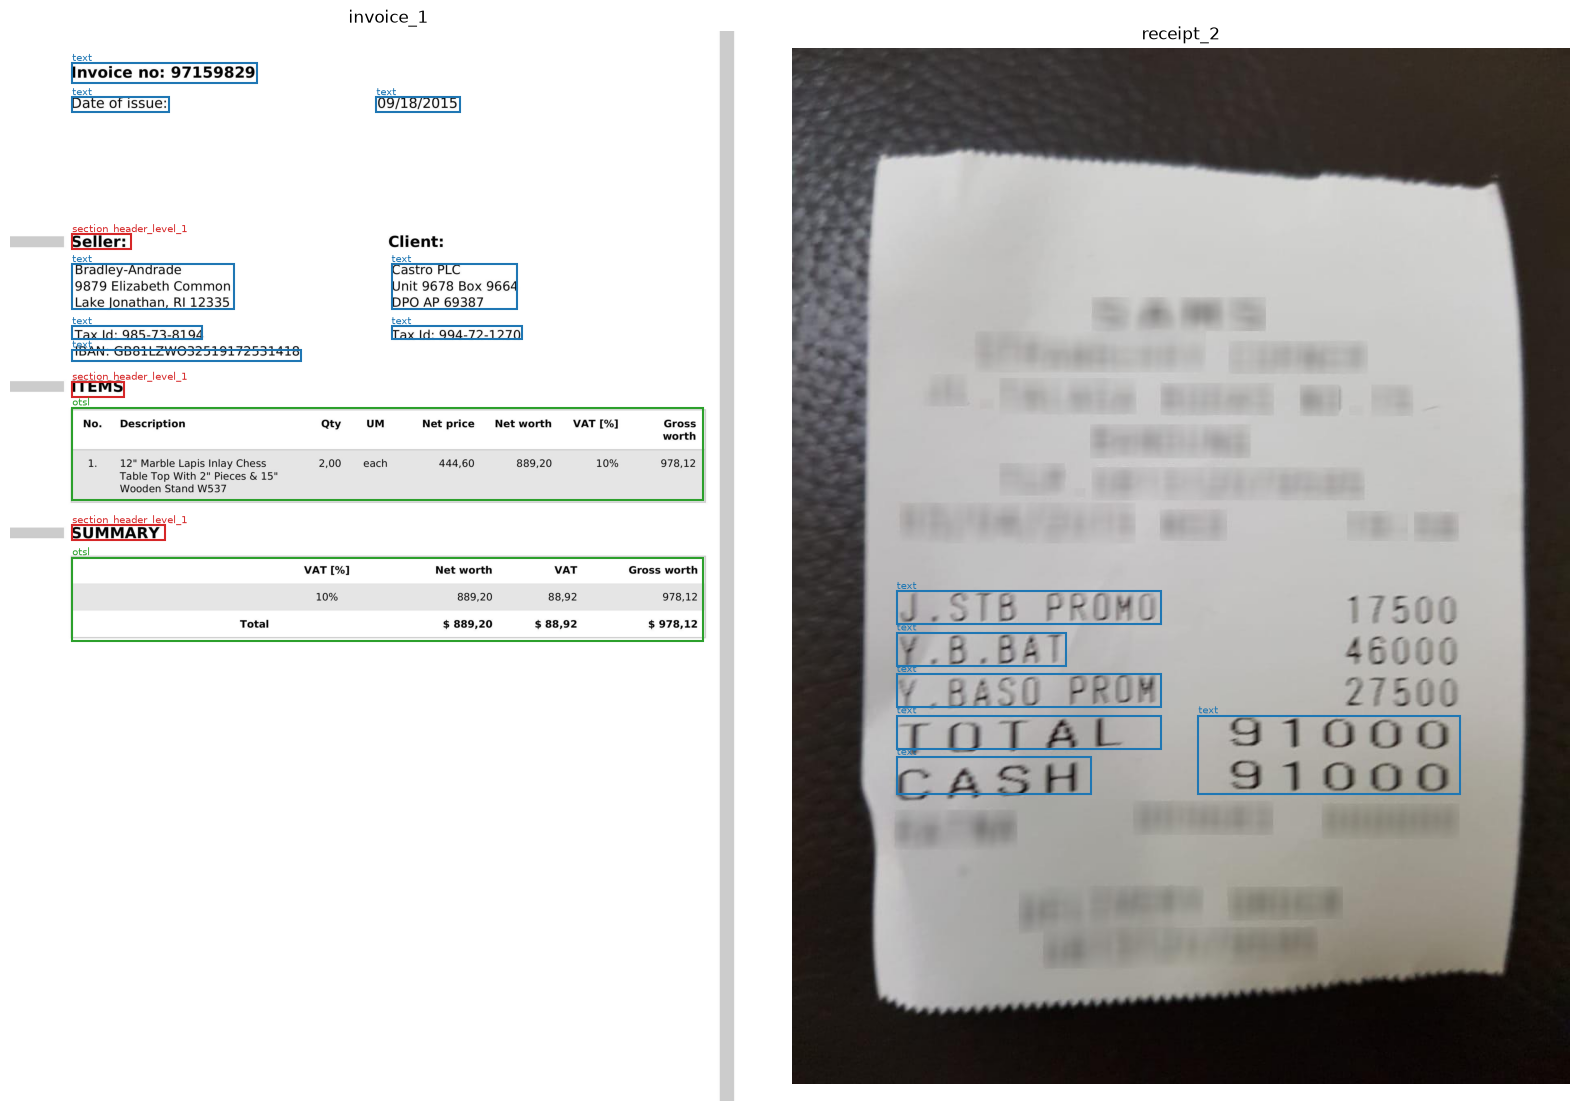

In [11]:
import re

def show_doctags_boxes(name, ax):
    img = IMAGES[name]; W, H = img.size
    ax.imshow(img); ax.axis("off")
    for m in re.finditer(r"<(\w+)><loc_(\d+)><loc_(\d+)><loc_(\d+)><loc_(\d+)>", DOCTAGS[name]):
        tag, x1, y1, x2, y2 = m.group(1), *map(int, m.groups()[1:])
        x1, x2, y1, y2 = x1 / 500 * W, x2 / 500 * W, y1 / 500 * H, y2 / 500 * H
        color = {"text": "tab:blue", "otsl": "tab:green", "section_header_level_1": "tab:red"}.get(tag, "tab:orange")
        ax.add_patch(mpatches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=color, lw=1.5))
        ax.text(x1, y1, tag, color=color, fontsize=7, va="bottom")
    ax.set_title(name)

fig, axes = plt.subplots(1, 2, figsize=(16, 11))
show_doctags_boxes("invoice_1", axes[0]); show_doctags_boxes("receipt_2", axes[1])
plt.tight_layout(); plt.show()

## 4. GOT-OCR 2.0 (580M vision-language model)

> **What it does:** GOT-OCR 2.0 ("General OCR Theory") is a 580M-parameter OCR model from StepFun: a vision encoder plus a small
> Qwen language model that **reads the image and writes out the text**. Besides plain text, its "format" mode writes Markdown
> or LaTeX (useful for tables and formulas), and it can also read sheet music, charts and geometry. It reads the image directly, with no Tesseract.
>
> | | |
> |---|---|
> | **Input** | page image (resized to 1024×1024 internally; `crop_to_patches=True` tiles large, dense pages) + `format=True/False` |
> | **Output** | text: plain by default, Markdown/LaTeX with `format=True`. No word boxes. |
> | **Needs from you** | just the image. On CPU, use bfloat16 if RAM is tight (done here). |
>
> **Example (invoice_1):** `Invoice no: 97159829 Date of issue: 09/18/2015 Seller: Client: Bradley- Andrade Castro PLC …`.
> Plain mode runs the two columns (seller and client) together. Format mode keeps the layout better.

In [12]:
GOT = "stepfun-ai/GOT-OCR-2.0-hf"
t = time.time()
got_proc = AutoProcessor.from_pretrained(GOT)
got_model = AutoModelForImageTextToText.from_pretrained(GOT, dtype=GOT_DTYPE).to(DEVICE).eval()
print(f"GOT-OCR loaded in {time.time() - t:.1f}s ({GOT_DTYPE})")

def got_read(img, fmt=False):
    inputs = got_proc(img, return_tensors="pt", format=fmt).to(DEVICE, GOT_DTYPE)
    with torch.inference_mode():
        gen = got_model.generate(**inputs, do_sample=False, tokenizer=got_proc.tokenizer,
                                 stop_strings="<|im_end|>", max_new_tokens=MAX_NEW_TOKENS)
    return got_proc.decode(gen[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

for name, img in IMAGES.items():
    t = time.time()
    record("got_ocr", name, got_read(img), time.time() - t)
    print(f"{name}: {TIMES['got_ocr'][name]:.1f}s", flush=True)
show_model("got_ocr")


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 471/471 [00:00<00:00, 6424.28it/s]

GOT-OCR loaded in 2.9s (torch.bfloat16)


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


invoice_1: 6.8s


invoice_2: 11.3s


... (6 outputs left out)

receipt_4: 2.3s


receipt_5: 3.1s


,fields found,missed,chars,seconds
doc,,,,
invoice_1,4/5,iban,535,6.8
invoice_2,5/5,,977,11.3
invoice_3,5/5,,453,6.2
invoice_4,4/5,iban,593,7.6
invoice_5,5/5,,1187,13.2
receipt_1,2/2,,139,3.0
receipt_2,2/2,,70,2.2
receipt_3,1/4,"total_price, subtotal_price, changeprice",107,2.5
receipt_4,3/3,,85,2.3


got_ocr: 35/40 answer-key values found (88%) | avg 5.8s per page


**Format mode** on one invoice (Markdown/LaTeX output instead of plain text):

In [13]:
t = time.time()
formatted = got_read(IMAGES["invoice_1"], fmt=True)
(OUT / "got_ocr" / "invoice_1_formatted.md").write_text(formatted)
print(f"{time.time() - t:.1f}s\n")
print(formatted[:1500])
free(got_model, got_proc)

8.0s

Invoice no: 97159829
Date of issue:
09/18/2015
\section*{Seller:}
Bradley-Andrade
9879 Elizabeth Common
Lake Jonathan, RI 12335
Tax Id: 985-73-8194
IBAN: GB81LZWO32519172531418
\section*{ITEMS}
\begin{tabular}{|c|c|c|c|c|c|c|}
\hline No. & Description & Qty & UM & Net price & Net worth & VAT [\%] \\
\hline 1. & \begin{tabular}{l}
\(12 "\) Marble Lapis Inlay Chess \\
Table Top With 2" Pieces \& 15" \\
Wooden Stand W537
\end{tabular} & 2,00 & each & 444,60 & 889,20 & \(10 \%\) \\
\hline
\end{tabular}
\section*{SUMMARY}
\begin{tabular}{|c|c|c|c|}
\hline & VAT [\%] & Net worth & VAT \\
\hline & \(10 \%\) & 889,20 & 88,92 \\
\hline & Total & \(\$ 889,20\) & \(\$ 88,92\) \\
\hline
\end{tabular}


## 5. Summary

- **OCR models:** the % of answer-key values each model's text contains exactly.
- **LayoutLM:** the % of questions answered exactly right.

In [14]:
OCR_MODELS = ["tesseract", "smoldocling", "got_ocr"]
rows = []
for m in OCR_MODELS:
    for kind in ["invoice", "receipt"]:
        found = [v for n, t in RESULTS[m].items() if n.startswith(kind) for v in fields_found(n, t).values()]
        secs = [s for n, s in TIMES[m].items() if n.startswith(kind)]
        rows.append({"model": m, "docs": kind + "s", "values found": f"{sum(found)}/{len(found)}",
                     "% found": round(100 * sum(found) / len(found)), "avg s / page": round(sum(secs) / len(secs), 1)})
for kind in ["invoice", "receipt"]:
    sub = QA[QA.doc.str.startswith(kind)]
    rows.append({"model": "layoutlm (+tesseract)", "docs": kind + "s", "values found": f"{sub.correct.sum()}/{len(sub)}",
                 "% found": round(100 * sub.correct.mean()), "avg s / page": round(sub.groupby("doc").seconds.sum().mean(), 1)})
SUMMARY = pd.DataFrame(rows)
SUMMARY.to_csv(OUT / "summary.csv", index=False)
display(SUMMARY.pivot(index="model", columns="docs", values=["% found", "avg s / page"]))

detail = pd.DataFrame({m: {f"{n}:{f}": ok for n, t in RESULTS[m].items() for f, ok in fields_found(n, t).items()}
                       for m in OCR_MODELS})
detail["layoutlm"] = QA.set_index(QA.doc + ":" + QA.question.map({q: f for f, q in QUESTIONS.items()})).correct
detail.insert(0, "expected", {f"{n}:{f}": v for n, kv in KEY.items() for f, v in kv.items()})
detail.to_csv(OUT / "field_check.csv")
print("Per-field check (True = value read exactly):")
display(detail.replace({True: "✓", False: "✗"}))

% found          avg s / page         
docs                  invoices receipts     invoices receipts
model                                                        
got_ocr                   92.0     80.0          9.0      2.6
layoutlm (+tesseract)     84.0      7.0          7.9      1.3
smoldocling               92.0     47.0         19.8     13.9
tesseract                 88.0     27.0          1.6      0.4

Per-field check (True = value read exactly):


,expected,tesseract,smoldocling,got_ocr,layoutlm
invoice_1:invoice_no,97159829,✓,✓,✓,✓
invoice_1:invoice_date,09/18/2015,✓,✓,✓,✓
invoice_1:seller_tax_id,985-73-8194,✓,✓,✓,✓
invoice_1:iban,GB81LZWO32519172531418,✗,✓,✗,✗
invoice_1:total_gross_worth,"978,12",✓,✓,✓,✓
invoice_2:invoice_no,13194726,✓,✓,✓,✓
invoice_2:invoice_date,05/29/2021,✓,✓,✓,✓
invoice_2:seller_tax_id,952-73-7223,✓,✓,✓,✓
invoice_2:iban,GB31LZX520242755934691,✗,✗,✓,✗
invoice_2:total_gross_worth,"640,12",✓,✓,✓,✓


## 6. Side-by-side: every model's output for one document

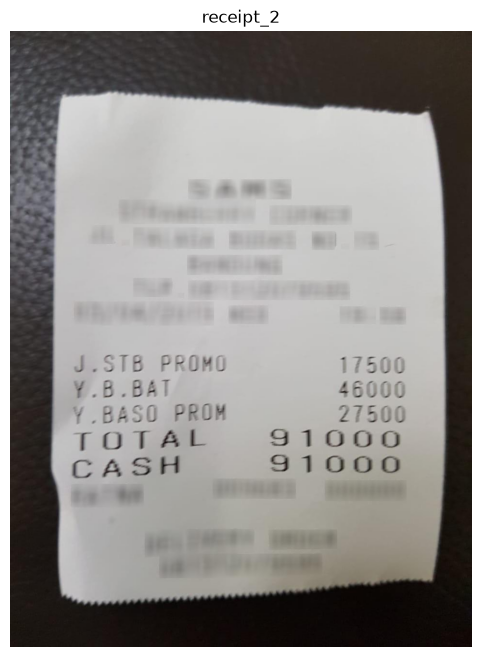

===== tesseract (0.4s) =====
 

===== smoldocling (5.3s) =====
J.STB PROMO

Y.B.BAT

Y.BASO PROM

TOTAL 91000

CASH 91000

91000 

===== got_ocr (2.2s) =====
J.STBPR0MO 17500 Y.B.BAT 46000 Y.BASOPROM 27500 TOTAL 91000 CASH 91000 

===== layoutlm answers =====


,question,answer,score,expected,correct
27,What is the total price?,,0.0,91000,False
28,How much cash was paid?,,0.0,91000,False


In [15]:
def compare(name, chars=900):
    plt.figure(figsize=(6, 8)); plt.imshow(IMAGES[name]); plt.axis("off"); plt.title(name); plt.show()
    for m in OCR_MODELS:
        print(f"===== {m} ({TIMES[m][name]:.1f}s) =====")
        print(RESULTS[m][name][:chars], "\n")
    print("===== layoutlm answers =====")
    display(QA[QA.doc == name][["question", "answer", "score", "expected", "correct"]])

compare("receipt_2")

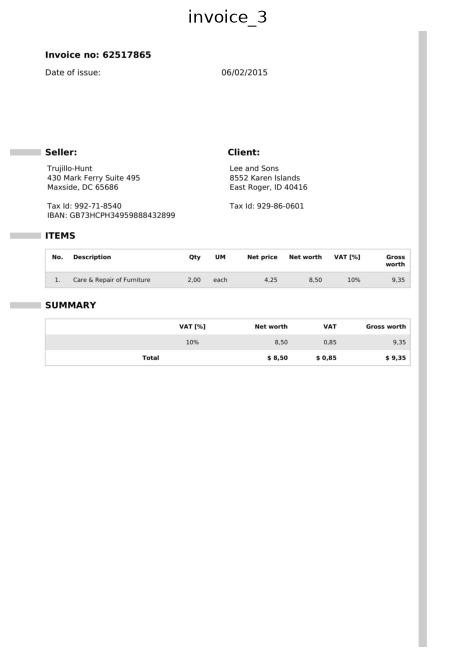

===== tesseract (1.1s) =====
Invoice no: 62517865

Date of issue:

Seller:

Trujillo-Hunt
430 Mark Ferry Suite 495
Maxside, DC 65686

Tax Id: 992-71-8540
IBAN: GB73HCPH34959888432899

ITEMS
No. Description Qty
1. Care & Repair of Furniture 2,00
SUMMARY
VAT [%]
10%
Total

UM

each

06/02/2015

Client:

Lee and Sons
8552 Karen Islands
East Roger, ID 40416

Tax Id: 929-86-0601

Net price Net worth VAT [%]
4,25 8,50 10%
Net worth VAT
8,50 0,85
$ 8,50 $ 0,85

Gross
worth

315

Gross worth
9,35

$ 9,35
 

===== smoldocling (13.1s) =====
Invoice no: 62517865

Date of issue:

06/02/2015

## Seller:

Trujillo-Hunt 430 Mark Ferry Suite 495 Maxside, DC 65686

Tax Id: 992-71-8540

IBAN: GB73HCPH34959888432899

## ITEMS

|   No. | Description                | Qty   | UM   | Net price   | Net worth   | VAT [%]   | Gross  worth   |
|-------|----------------------------|-------|------|-------------|-------------|-----------|----------------|
|    1. | Care & Repair of Furniture | 2,00  | each | 4,25  

,question,answer,score,expected,correct
10,What is the invoice number?,62517865,1.000,62517865,True
11,What is the date of issue?,06/02/2015,1.000,06/02/2015,True
12,What is the seller's tax id?,992-71-8540,1.000,992-71-8540,True
13,What is the IBAN?,GB73HCPH34959888432899,1.000,GB73HCPH34959888432899,True
14,What is the total gross worth?,315,0.504,"9,35",False


In [16]:
compare("invoice_3")

## 7. Boxes side by side: Tesseract, SmolDocling, GOT-OCR

The three models give very different location information:

- **Tesseract:** a box for every **word** (colour = confidence: green ≥ 80, orange 50–80, red < 50).
- **SmolDocling:** a box for every **element** (line, paragraph, table, header) on a 0–500 grid, not per word.
- **GOT-OCR:** **no boxes**, only text. To still show it on the page, Tesseract's word boxes are reused and coloured by
  whether GOT's text contains that word (green = GOT has it, red = GOT does not). The boxes are Tesseract's, not GOT's.
  Very short tokens (e.g. `1.`, `%`) almost always count as found.

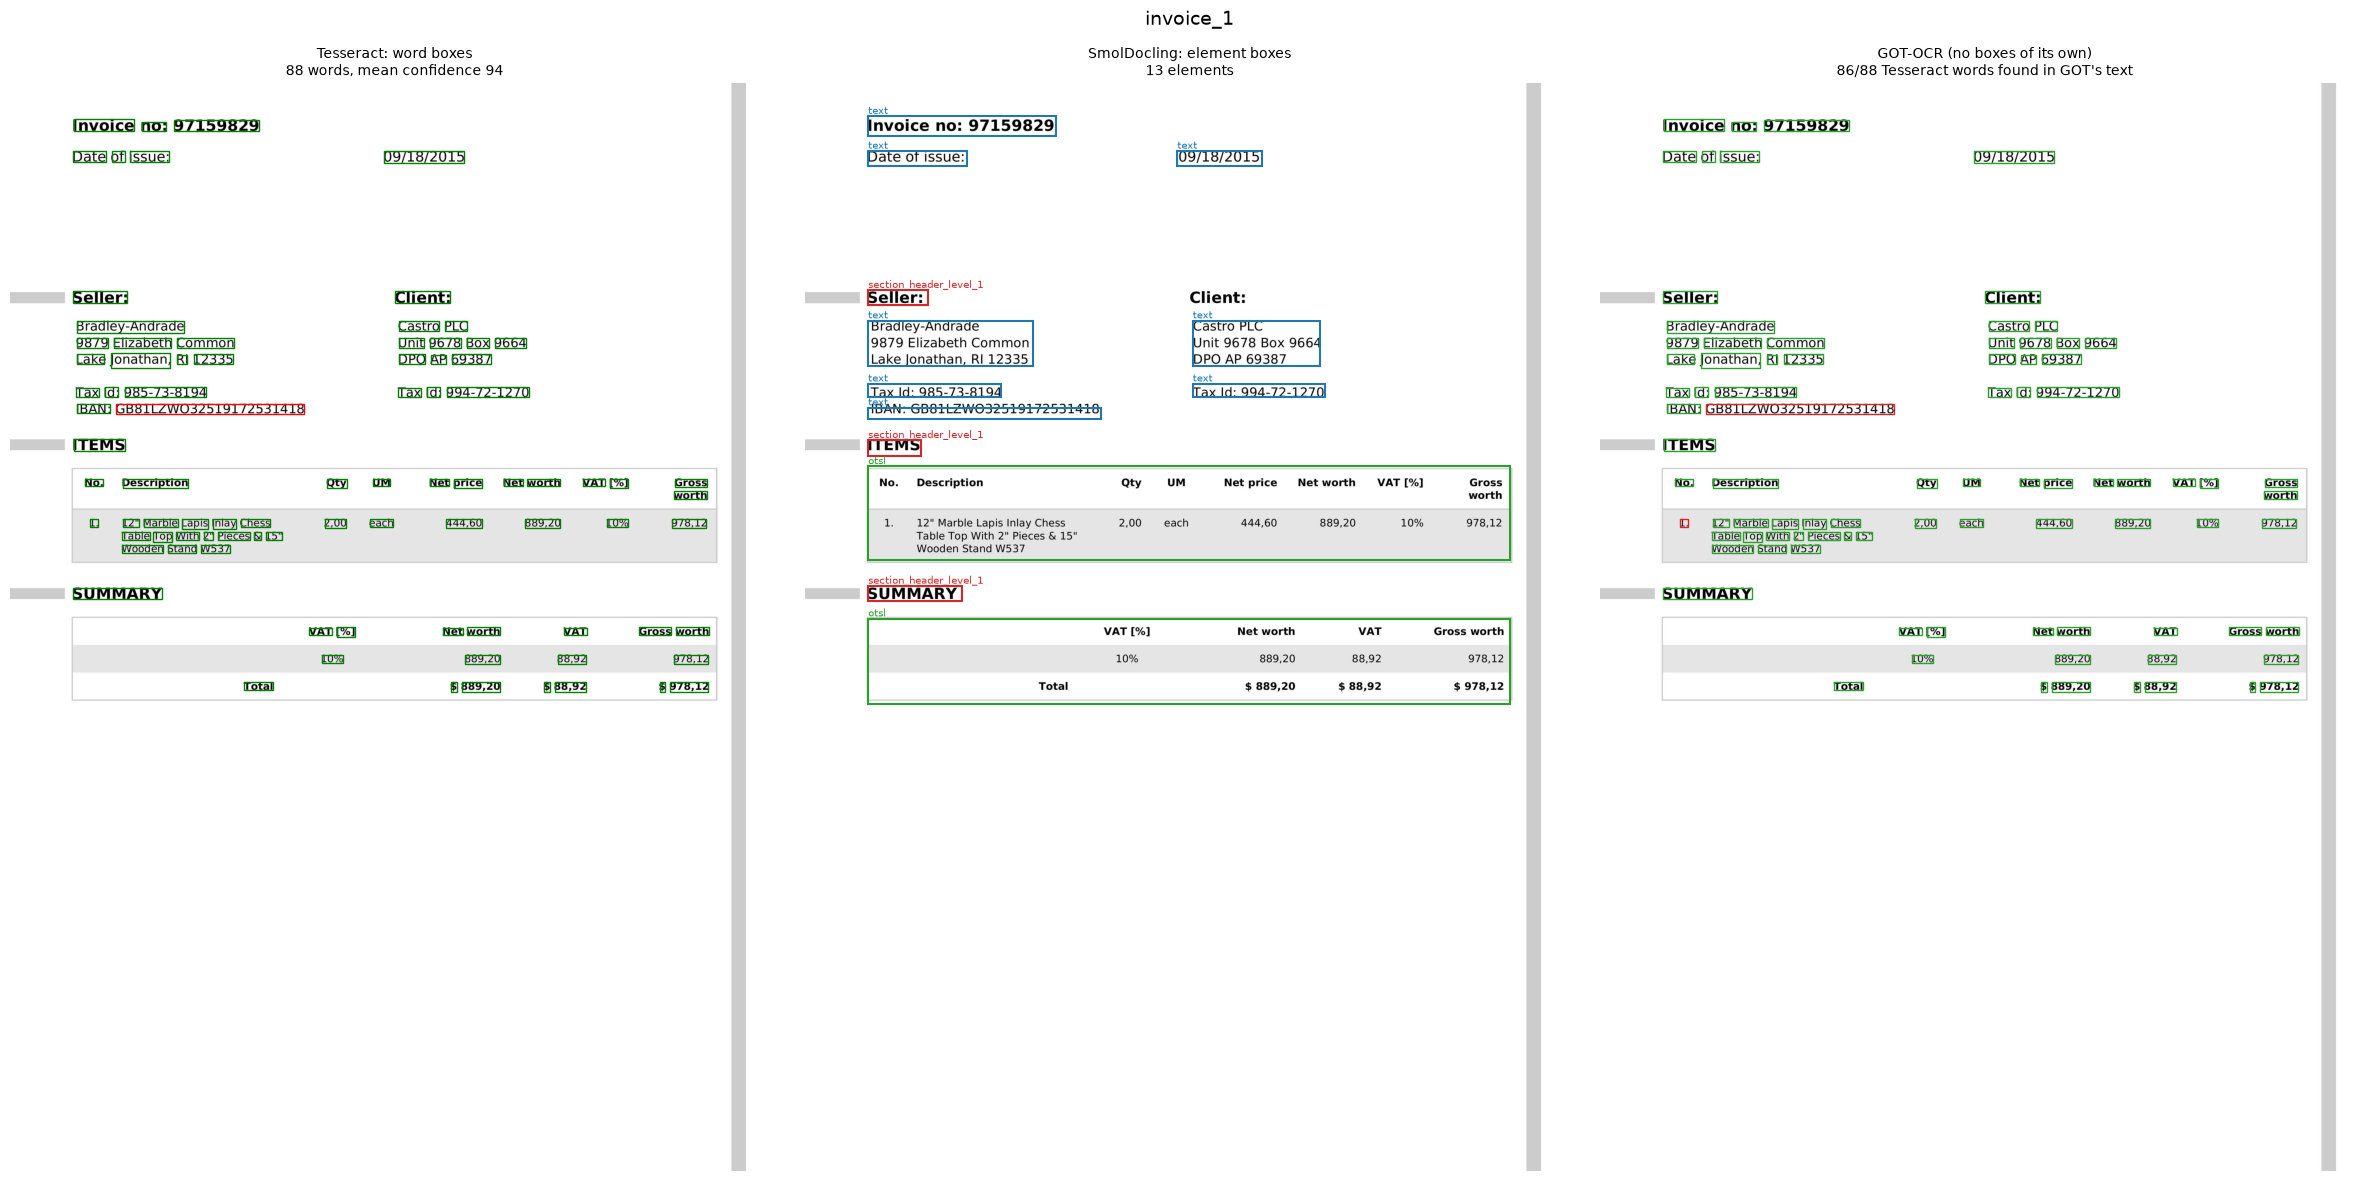

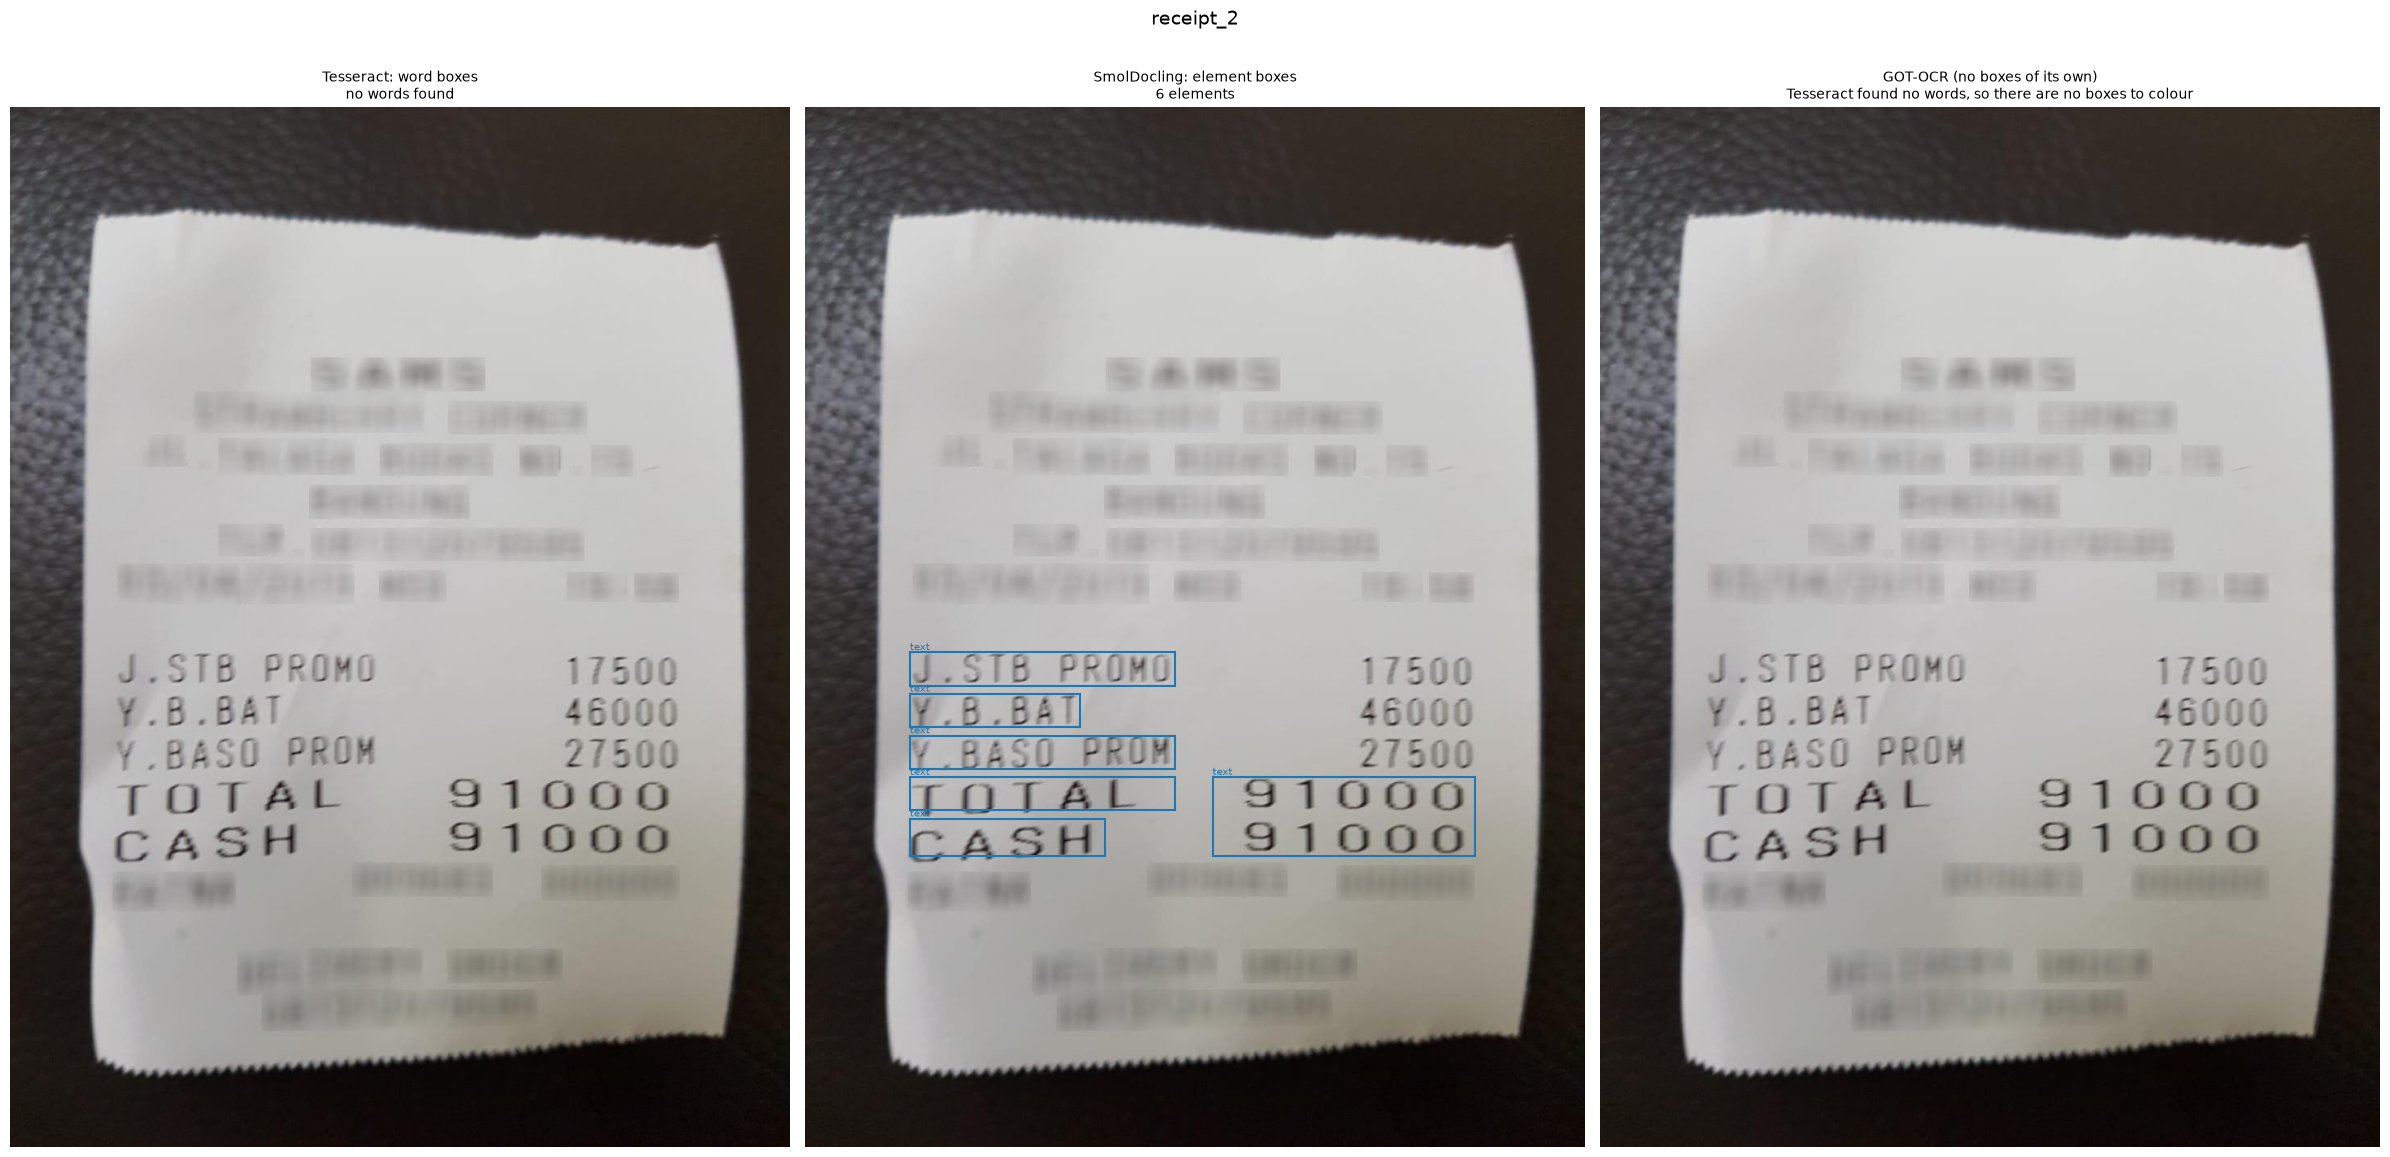

In [17]:
def show_got_on_tesseract_boxes(name, ax):
    img = IMAGES[name]
    d = pytesseract.image_to_data(img, output_type=pytesseract.Output.DATAFRAME)
    d = d[(d.conf > 0) & d.text.astype(str).str.strip().ne("")]
    got = norm(RESULTS["got_ocr"][name])
    ax.imshow(img); ax.axis("off")
    hits = 0
    for _, w in d.iterrows():
        ok = norm(w.text) in got
        hits += ok
        ax.add_patch(mpatches.Rectangle((w.left, w.top), w.width, w.height, fill=False,
                                        ec="tab:green" if ok else "tab:red", lw=1))
    if len(d):
        ax.set_title(f"GOT-OCR (no boxes of its own)\n{hits}/{len(d)} Tesseract words found in GOT's text", fontsize=10)
    else:
        ax.set_title("GOT-OCR (no boxes of its own)\nTesseract found no words, so there are no boxes to colour", fontsize=10)

def side_by_side(name):
    fig, axes = plt.subplots(1, 3, figsize=(24, 12))
    d = show_words(name, axes[0])
    axes[0].set_title(f"Tesseract: word boxes\n{len(d)} words, mean confidence {d.conf.mean():.0f}" if len(d)
                      else "Tesseract: word boxes\nno words found", fontsize=10)
    show_doctags_boxes(name, axes[1])
    n_el = len(re.findall(r"<\w+><loc_\d+><loc_\d+><loc_\d+><loc_\d+>", DOCTAGS[name]))
    axes[1].set_title(f"SmolDocling: element boxes\n{n_el} elements", fontsize=10)
    show_got_on_tesseract_boxes(name, axes[2])
    fig.suptitle(name, fontsize=14)
    plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

for name in ["invoice_1", "receipt_2"]:
    side_by_side(name)